# IEEE 13-bus one-shot DDPG training and reference comparison

## Purpose

This notebook trains, evaluates, or views one-shot DDPG runs against neutral taps and native RegControl. Each hourly scenario is independent and starts from neutral taps. Results describe this saved validation split and synthetic process; they do not establish convergence or general performance.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
if not (ROOT / "src/feeder").is_dir():
    raise RuntimeError("Start the kernel in the notebook directory (experiments/<feeder>/).")
sys.path.insert(0, str(ROOT / "src"))

from common.reports import show_conclusions, show_controller_comparison, show_paired_counts, show_tap_sample, show_training_summary
from common.workflow import run_experiment

ROOT  # Confirm the resolved repository root.

PosixPath('/home/dev/src/ailearn/phd')

## Parameters

Edit this cell, then restart the kernel and run all cells. `MODE` selects `train`, `evaluate`, or read-only `view`; `OVERWRITE` affects only writing modes. The former `TRAIN = True` maps to `MODE = "train"`, while `TRAIN = False` with evaluation maps to `MODE = "evaluate"`; use `view` for saved results.

In [2]:
FEEDER = "ieee13"  # Named feeder.
DATASET = "ieee13-random"  # Named dataset.
SEEDS = [0, 1, 2]  # Independent training seeds.
MODE = "view"  # train, evaluate, or read saved results.
OVERWRITE = False  # Applies only to train and evaluate.
EPISODES = 20000  # Training only: interactions per run.
SPLIT = "validation"  # Evaluation split.
EVALUATION_DAYS = None  # Complete split or a positive day limit.
REWARD = "voltage_band"  # Training only: reward name.
MAD_WEIGHT = 0.0  # Training only: voltage-deviation reward weight.
RUN_PREFIX = "seed"  # Prefix for each run name.

**Units and interfaces.** Solver voltages and executed tap ratios use physical p.u. values; tap positions are integer grid indices. The network receives normalized voltage features. Training reward is dimensionless, while reported voltage cost is mean squared excursion outside [0.95, 1.05] p.u.

In [3]:
results = run_experiment({
    "protocol": "one_shot",
    "algorithm": "ddpg",
    "feeder": FEEDER,
    "dataset": DATASET,
    "seeds": SEEDS,
    "mode": MODE,
    "overwrite": OVERWRITE,
    "episodes": EPISODES,
    "split": SPLIT,
    "evaluation_days": EVALUATION_DAYS,
    "reward": REWARD,
    "mad_weight": MAD_WEIGHT,
    "run_prefix": RUN_PREFIX,
    "root": ROOT,
})

Dataset: ieee13-random (data/scenarios/ieee13-random)
Split: validation
Evaluated: 200 days, 4800 hours
Seeds: [0, 1, 2]
Display names and run directories:
  DDPG seed 0: results/ieee13-random/ddpg/seed0/
  DDPG seed 1: results/ieee13-random/ddpg/seed1/
  DDPG seed 2: results/ieee13-random/ddpg/seed2/
  Neutral: results/ieee13-random/reference/neutral/
  RegControl: results/ieee13-random/reference/regcontrol/
Mode: view
Overwrite: False
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.
Scenario alignment passed for 4800 hours and 5 methods.


## Training records

An episode is one independent scenario and action. Higher reward is better. Training includes exploration, so these curves are not held-out performance or proof of convergence.

Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training episodes
DDPG seed 0,voltage_band,"{'mad_weight': 0.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000
DDPG seed 1,voltage_band,"{'mad_weight': 0.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000
DDPG seed 2,voltage_band,"{'mad_weight': 0.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",None,"[400, 300]",20000


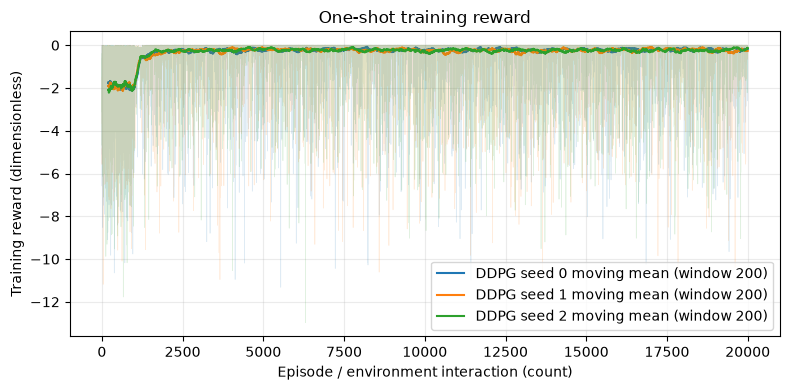

Completed training episodes: {'seed0': 20000, 'seed1': 20000, 'seed2': 20000}


In [4]:
show_training_summary(results)

## Overall comparison

Every method uses the same ordered scenarios. Feasibility means convergence with every monitored voltage inside [0.95, 1.05] p.u.; violation count counts measurements, not hours. Across-seed sample standard deviation describes run-level spread, not a confidence interval.

Neutral holds every regulator ratio at 1.0. RegControl uses the feeder's native regulator control.

Hourly voltage cost is the mean squared excursion outside [0.95, 1.05] p.u. over 41 monitored line-ground voltage measurements; in-band measurements contribute zero. Lower cost is better.

Method,Mean hourly voltage cost,Feasible scenarios (%),Mean violating voltage measurements/scenario,Scenarios
DDPG seed 0,1.427e-05,36.6,2.42,4800
DDPG seed 1,1.423e-05,22.2,6.05,4800
DDPG seed 2,1.207e-05,43.7,4.47,4800
Neutral,0.0006713,14.0,15.80,4800
RegControl,1.934e-05,27.2,4.63,4800


DDPG statistic,Mean hourly voltage cost,Feasible scenarios (%),Mean violating voltage measurements/scenario
Across-seed mean,1.352e-05,34.2,4.32
Sample standard deviation,1.259e-06,10.9,1.82


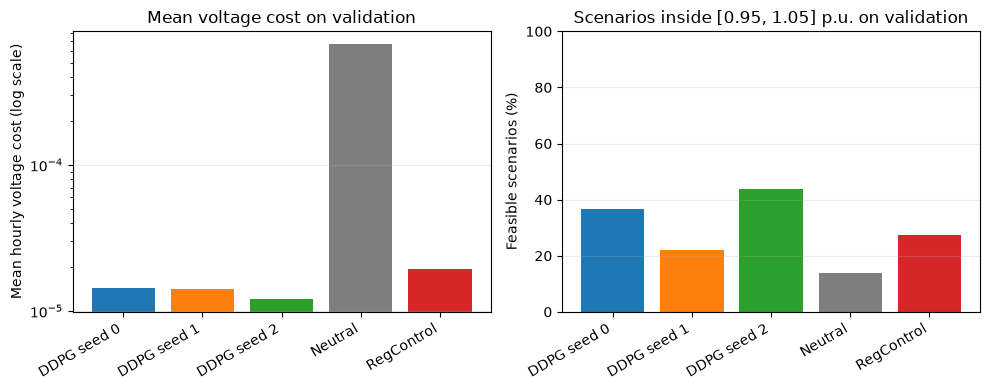

The voltage-cost panel uses a log scale because every displayed cost is positive. Log spacing shows multiplicative differences.

In [5]:
show_controller_comparison(results)

### Executed tap settings

Ratios are executed regulator settings, not bus voltages. Neutral is 1.0; legal ratios span 0.90 to 1.10 in 0.00625 steps. The five loading ranks are illustrative rather than aggregate evidence.

Scenario,Loading multiplier,Method,Ratio 1,Ratio 2,Ratio 3
validation-0128-h15,0.500193,DDPG seed 0,1.03125,1,0.99375
validation-0128-h15,0.500193,DDPG seed 1,0.9875,1.0125,0.99375
validation-0128-h15,0.500193,DDPG seed 2,1.0125,1.0125,0.99375
validation-0128-h15,0.500193,Neutral,1,1,1
validation-0128-h15,0.500193,RegControl,1.0375,1.03125,1.0375
validation-0013-h10,0.747177,DDPG seed 0,1.04375,1.0125,1.0125
validation-0013-h10,0.747177,DDPG seed 1,1.00625,1.01875,1.01875
validation-0013-h10,0.747177,DDPG seed 2,1.025,1.01875,1.01875
validation-0013-h10,0.747177,Neutral,1,1,1
validation-0013-h10,0.747177,RegControl,1.05,1.0375,1.05


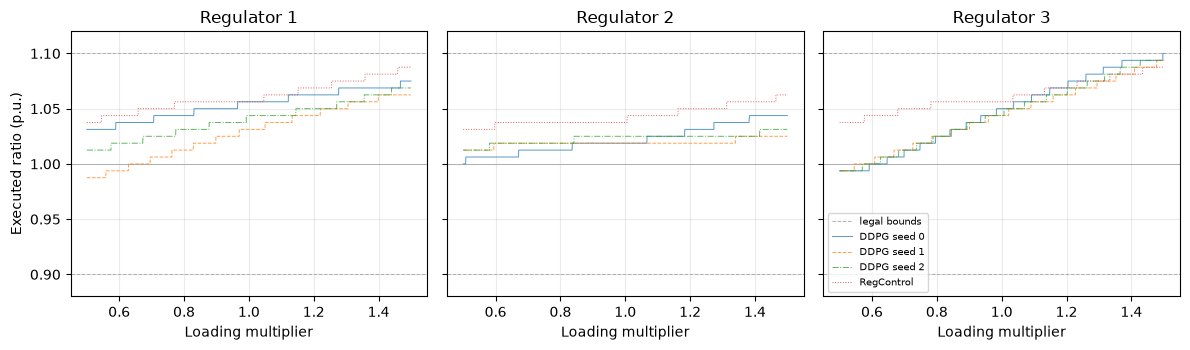

The x-axis orders independent scenarios by loading multiplier, not time. Connecting lines aid reading; they are not trajectories or continuous actions.

In [6]:
show_tap_sample(results)

### Paired cost counts

Counts compare exact saved voltage costs on matched scenarios. Equality is exact, not a practical-equivalence test, and counts do not show improvement size.

In [7]:
show_paired_counts(results)

DDPG run,Reference,Lower-cost scenarios,Equal-cost scenarios,Higher-cost scenarios
DDPG seed 0,Neutral,4127,645,28
DDPG seed 0,RegControl,3419,1063,318
DDPG seed 1,Neutral,4127,411,262
DDPG seed 1,RegControl,3420,760,620
DDPG seed 2,Neutral,4127,673,0
DDPG seed 2,RegControl,3493,1280,27


## Conclusions

In [8]:
show_conclusions(results)

The validation evaluation covers 4800 independent scenarios for 3 DDPG seeds and 20000 training episodes per seed.

Across 3 independent seeds, DDPG mean hourly voltage cost is 1.352e-05 with sample standard deviation 1.259e-06. This is lower than Neutral (0.0006713) and lower than RegControl (1.934e-05).

Across 3 independent seeds, DDPG feasible scenarios average 34.2% with sample standard deviation 10.9 percentage points; this is higher than Neutral (14.0%) and higher than RegControl (27.2%).

These results are limited to the validation split, this synthetic process, and the recorded training budget.